In [1]:
# Check GPU availability
!nvidia-smi

Sat Dec  6 14:21:21 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip uninstall -y numpy opencv-python opencv-python-headless scipy librosa numba llvmlite

!pip install numpy==2.0.2
!pip install scipy==1.16.3
!pip install opencv-python-headless==4.12.0.88
!pip install librosa==0.10.2.post1
!pip install numba==0.62.1
!pip install tqdm
!pip install gdown
!apt-get install -y ffmpeg


Found existing installation: numpy 2.0.2
Uninstalling numpy-2.0.2:
  Successfully uninstalled numpy-2.0.2
Found existing installation: opencv-python 4.12.0.88
Uninstalling opencv-python-4.12.0.88:
  Successfully uninstalled opencv-python-4.12.0.88
Found existing installation: opencv-python-headless 4.12.0.88
Uninstalling opencv-python-headless-4.12.0.88:
  Successfully uninstalled opencv-python-headless-4.12.0.88
Found existing installation: scipy 1.16.3
Uninstalling scipy-1.16.3:
  Successfully uninstalled scipy-1.16.3
Found existing installation: librosa 0.11.0
Uninstalling librosa-0.11.0:
  Successfully uninstalled librosa-0.11.0
Found existing installation: numba 0.60.0
Uninstalling numba-0.60.0:
  Successfully uninstalled numba-0.60.0
Found existing installation: llvmlite 0.43.0
Uninstalling llvmlite-0.43.0:
  Successfully uninstalled llvmlite-0.43.0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.2/19.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.7/35.7 MB 39.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
stumpy 1.13.0 requires numba>=0.57.1, which is not installed.
cuml-cu12 25.10.0 requires numba<0.62.0a0,>=0.60.0, which is not installed.
shap 0.50.0 requires numba>=0.54; python_version < "3.14", which is not installed.
quantecon 0.10.1 requires numba>=0.49.0, which is not installed.
segregation 2.5.3 requires numba, which is not installed.
albumentations 2.0.8 requires opencv-python-headless>=4.9.0.80, which is not installed.
pynndescent 0.5.13 requires llvmlite>=0.30, which is not installed.
pynndescent 0.5.13 requires numba>=0.51.2, which is not installed.
umap-learn 0.5.9.post2 requires numba>=0.51.2, which is not installed.
dopamine-rl 4.1.2 requires o

In [3]:
import numpy, cv2, scipy, librosa, numba
print("NumPy:", numpy.__version__)
print("OpenCV:", cv2.__version__)
print("SciPy:", scipy.__version__)
print("Librosa:", librosa.__version__)
print("Numba:", numba.__version__)

NumPy: 2.0.2
OpenCV: 4.12.0
SciPy: 1.16.3
Librosa: 0.10.2.post1
Numba: 0.62.1


In [4]:
import os

# Create necessary directories
directories = [
    'dataset/videos',
    'dataset/audio',
    'dataset/images',
    'dataset/preprocessed',
    'outputs',
    'models'
]

for dir_path in directories:
    os.makedirs(dir_path, exist_ok=True)

print("Directory structure created!")

Directory structure created!


In [5]:
from google.colab import files
import shutil

print("Upload your video file:")
uploaded = files.upload()

# Move uploaded file to dataset folder
for filename in uploaded.keys():
    shutil.move(filename, f'dataset/videos/{filename}')
    print(f"Uploaded: {filename}")

Upload your video file:


Saving video.mp4 to video.mp4
Uploaded: video.mp4


In [6]:
import subprocess

def extract_audio(video_path, output_audio_path):
    """Extract audio from video file"""
    command = f'ffmpeg -i {video_path} -ab 160k -ac 2 -ar 44100 -vn {output_audio_path}'
    subprocess.call(command, shell=True)
    print(f"✅ Audio extracted: {output_audio_path}")

# Extract audio from all videos
video_files = [f for f in os.listdir('dataset/videos') if f.endswith(('.mp4', '.avi', '.mov'))]

for video_file in video_files:
    video_path = f'dataset/videos/{video_file}'
    audio_path = f'dataset/audio/{video_file.rsplit(".", 1)[0]}.wav'
    extract_audio(video_path, audio_path)

✅ Audio extracted: dataset/audio/video.wav


In [7]:
import cv2
import numpy as np
from tqdm import tqdm

def extract_frames(video_path, output_folder):
    """Extract all frames from video"""
    os.makedirs(output_folder, exist_ok=True)

    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print(f"Video Info: {frame_count} frames at {fps} FPS")

    frames = []
    idx = 0

    with tqdm(total=frame_count, desc="Extracting frames") as pbar:
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break

            # Save frame
            frame_path = f"{output_folder}/frame_{idx:06d}.jpg"
            cv2.imwrite(frame_path, frame)
            frames.append(frame)
            idx += 1
            pbar.update(1)

    cap.release()
    print(f"Extracted {idx} frames")
    return frames, fps

# Extract frames from first video
video_file = video_files[0]
video_path = f'dataset/videos/{video_file}'
output_folder = f'dataset/preprocessed/{video_file.rsplit(".", 1)[0]}_frames'

frames, fps = extract_frames(video_path, output_folder)

Video Info: 261 frames at 24.0 FPS


Extracting frames: 100%|██████████| 261/261 [00:01<00:00, 250.84it/s]

Extracted 261 frames


In [8]:
def detect_and_align_faces(frames_folder):
    """Detect faces in frames and perform alignment"""
    # Load OpenCV's pre-trained face detector
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

    frame_files = sorted([f for f in os.listdir(frames_folder) if f.endswith('.jpg')])
    face_data = []

    print("🔍 Detecting faces...")

    for frame_file in tqdm(frame_files[:100]):  # Process first 100 frames for demo
        frame_path = os.path.join(frames_folder, frame_file)
        img = cv2.imread(frame_path)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # Detect faces
        faces = face_cascade.detectMultiScale(gray, 1.3, 5)

        if len(faces) > 0:
            # Get largest face
            x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
            face_data.append({
                'frame': frame_file,
                'bbox': (x, y, w, h),
                'center': (x + w//2, y + h//2)
            })

    print(f"Detected faces in {len(face_data)} frames")
    return face_data

face_data = detect_and_align_faces(output_folder)

🔍 Detecting faces...


100%|██████████| 100/100 [00:10<00:00,  9.64it/s]

Detected faces in 100 frames


In [9]:
# Clone Wav2Lip
!git clone https://github.com/Rudrabha/Wav2Lip.git
%cd Wav2Lip

print("Wav2Lip cloned!")

Cloning into 'Wav2Lip'...
remote: Enumerating objects: 409, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 409 (delta 2), reused 0 (delta 0), pack-reused 405 (from 2)
Receiving objects: 100% (409/409), 549.05 KiB | 18.93 MiB/s, done.
Resolving deltas: 100% (227/227), done.
/content/Wav2Lip
Wav2Lip cloned!


In [10]:
!mkdir -p Wav2Lip/checkpoints
!mkdir -p Wav2Lip/face_detection/detection/sfd

!wget https://huggingface.co/akhaliq/Wav2Lip/resolve/main/wav2lip_gan.pth -O Wav2Lip/checkpoints/wav2lip.pth
!wget https://www.adrianbulat.com/downloads/python-fan/s3fd-619a316812.pth -O Wav2Lip/face_detection/detection/sfd/s3fd.pth


--2025-12-06 14:23:11--  https://huggingface.co/akhaliq/Wav2Lip/resolve/main/wav2lip_gan.pth
Resolving huggingface.co (huggingface.co)... 13.35.202.40, 13.35.202.121, 13.35.202.97, ...
Connecting to huggingface.co (huggingface.co)|13.35.202.40|:443... connected.
HTTP request sent, awaiting response... 401 Unauthorized

Username/Password Authentication Failed.
--2025-12-06 14:23:12--  https://www.adrianbulat.com/downloads/python-fan/s3fd-619a316812.pth
Resolving www.adrianbulat.com (www.adrianbulat.com)... 45.136.29.207
Connecting to www.adrianbulat.com (www.adrianbulat.com)|45.136.29.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 89843225 (86M) [application/octet-stream]
Saving to: ‘Wav2Lip/face_detection/detection/sfd/s3fd.pth’

Wav2Lip/face_detect 100%[===================>]  85.68M  3.56MB/s    in 28s     

2025-12-06 14:23:41 (3.01 MB/s) - ‘Wav2Lip/face_detection/detection/sfd/s3fd.pth’ saved [89843225/89843225]



In [11]:
# Go back to main directory
%cd ..

# Copy your video and audio to Wav2Lip folder
!cp dataset/videos/{video_files[0]} Wav2Lip/sample_video.mp4
!cp dataset/audio/{video_files[0].rsplit('.', 1)[0]}.wav Wav2Lip/sample_audio.wav

print("Files prepared for Wav2Lip!")

/content
Files prepared for Wav2Lip!


In [12]:
%cd /content
%cd Wav2Lip
!ls

/content
/content/Wav2Lip
audio.py		filelists	     preprocess.py     sample_video.mp4
checkpoints		hparams.py	     README.md	       temp
color_syncnet_train.py	hq_wav2lip_train.py  requirements.txt  Wav2Lip
evaluation		inference.py	     results	       wav2lip_train.py
face_detection		models		     sample_audio.wav


In [13]:
%cd /content/Wav2Lip
!rm -f checkpoints/wav2lip.pth


/content/Wav2Lip


In [14]:
%cd /content/Wav2Lip
!mkdir -p checkpoints
!mkdir -p face_detection/detection/sfd

/content/Wav2Lip


In [15]:
!wget https://www.adrianbulat.com/downloads/python-fan/s3fd-619a316812.pth -O face_detection/detection/sfd/s3fd.pth

--2025-12-06 14:23:42--  https://www.adrianbulat.com/downloads/python-fan/s3fd-619a316812.pth
Resolving www.adrianbulat.com (www.adrianbulat.com)... 45.136.29.207
Connecting to www.adrianbulat.com (www.adrianbulat.com)|45.136.29.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 89843225 (86M) [application/octet-stream]
Saving to: ‘face_detection/detection/sfd/s3fd.pth’

face_detection/dete 100%[===================>]  85.68M  12.5MB/s    in 7.8s    

2025-12-06 14:23:52 (11.0 MB/s) - ‘face_detection/detection/sfd/s3fd.pth’ saved [89843225/89843225]



In [16]:
!wget -O checkpoints/wav2lip_gan.pth \
  "https://github.com/anothermartz/Easy-Wav2Lip/releases/download/Prerequesits/Wav2Lip_GAN.pth"

--2025-12-06 14:23:52--  https://github.com/anothermartz/Easy-Wav2Lip/releases/download/Prerequesits/Wav2Lip_GAN.pth
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/625860988/86589224-d2a2-4209-84f4-9b9475d069e5?sp=r&sv=2018-11-09&sr=b&spr=https&se=2025-12-06T15%3A24%3A31Z&rscd=attachment%3B+filename%3DWav2Lip_GAN.pth&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2025-12-06T14%3A23%3A47Z&ske=2025-12-06T15%3A24%3A31Z&sks=b&skv=2018-11-09&sig=vAZbaCIi95jzKTk18QnWjt44QN28%2BGce%2B%2FbPcIZEw3A%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc2NTAzNDYzMiwibmJmIjoxNzY1MDMxMDMyLCJwYXRoIjoicmVsZWFzZWFz

In [17]:
!ls -lh checkpoints/
!ls -lh face_detection/detection/sfd/

total 416M
-rw-r--r-- 1 root root   46 Dec  6 14:23 README.md
-rw-r--r-- 1 root root 416M Oct 18  2023 wav2lip_gan.pth
total 86M
-rw-r--r-- 1 root root 4.2K Dec  6 14:23 bbox.py
-rw-r--r-- 1 root root 3.7K Dec  6 14:23 detect.py
-rw-r--r-- 1 root root   53 Dec  6 14:23 __init__.py
-rw-r--r-- 1 root root 5.2K Dec  6 14:23 net_s3fd.py
-rw-r--r-- 1 root root  86M Sep  2  2020 s3fd.pth
-rw-r--r-- 1 root root 1.8K Dec  6 14:23 sfd_detector.py


In [18]:
%cd /content/Wav2Lip
!sed -i 's/librosa.filters.mel(hp.sample_rate, hp.n_fft, n_mels=hp.num_mels,/librosa.filters.mel(sr=hp.sample_rate, n_fft=hp.n_fft, n_mels=hp.num_mels,/' audio.py
!grep "filters.mel" audio.py

/content/Wav2Lip
    return librosa.filters.mel(sr=hp.sample_rate, n_fft=hp.n_fft, n_mels=hp.num_mels,


In [19]:
%cd /content
!cp new_audio.wav Wav2Lip/sample_audio.wav

/content


In [20]:
!ls Wav2Lip | grep sample_audio.wav

sample_audio.wav


In [21]:
%cd /content/Wav2Lip

!python inference.py \
--checkpoint_path checkpoints/wav2lip_gan.pth \
--face sample_video.mp4 \
--audio sample_audio.wav \
--outfile results/result_lipsync_NEW.mp4 \
--resize_factor 2 \
--nosmooth

/content/Wav2Lip
Using cuda for inference.
Reading video frames...
Number of frames available for inference: 261
(80, 989)
Length of mel chunks: 294
  0% 0/3 [00:00<?, ?it/s]
  0% 0/17 [00:00<?, ?it/s]
  6% 1/17 [00:07<01:59,  7.50s/it]
 12% 2/17 [00:07<00:50,  3.35s/it]
 18% 3/17 [00:08<00:28,  2.02s/it]
 24% 4/17 [00:08<00:18,  1.41s/it]
 29% 5/17 [00:09<00:12,  1.07s/it]
 35% 6/17 [00:09<00:09,  1.19it/s]
 41% 7/17 [00:10<00:06,  1.45it/s]
 47% 8/17 [00:10<00:05,  1.70it/s]
 53% 9/17 [00:10<00:04,  1.93it/s]
 59% 10/17 [00:11<00:03,  2.11it/s]
 65% 11/17 [00:11<00:02,  2.23it/s]
 71% 12/17 [00:12<00:02,  2.30it/s]
 76% 13/17 [00:12<00:01,  2.39it/s]
 82% 14/17 [00:12<00:01,  2.46it/s]
 88% 15/17 [00:13<00:00,  2.51it/s]
 94% 16/17 [00:13<00:00,  2.54it/s]
100% 17/17 [00:15<00:00,  1.09it/s]
Load checkpoint from: checkpoints/wav2lip_gan.pth
Model loaded
100% 3/3 [00:31<00:00, 10.65s/it]
ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with g

In [22]:
from IPython.display import HTML
from base64 import b64encode

# Display original video
print("📹 ORIGINAL VIDEO:")
video_path = "../dataset/videos/" + video_files[0]
mp4 = open(video_path,'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML(f"""
<video width=400 controls>
      <source src="{data_url}" type="video/mp4">
</video>
""")

📹 ORIGINAL VIDEO:


In [23]:
from IPython.display import HTML
from base64 import b64encode

print("LIP-SYNCED VIDEO (NEW AUDIO):")

result_path = "/content/Wav2Lip/results/result_lipsync_NEW.mp4"
mp4 = open(result_path, 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

HTML(f"""
<video width=400 controls>
  <source src="{data_url}" type="video/mp4">
</video>
""")

LIP-SYNCED VIDEO (NEW AUDIO):


In [24]:
import numpy as np
from scipy.spatial import distance

def calculate_lip_sync_confidence(video_path):
    """
    Calculate lip-sync quality metrics
    """
    cap = cv2.VideoCapture(video_path)

    # Load face detector
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

    mouth_movements = []
    frame_count = 0

    while cap.isOpened() and frame_count < 100:  # Sample first 100 frames
        ret, frame = cap.read()
        if not ret:
            break

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray, 1.3, 5)

        if len(faces) > 0:
            x, y, w, h = faces[0]
            # Mouth region (lower third of face)
            mouth_region = gray[y+int(h*0.6):y+h, x:x+w]
            mouth_movements.append(np.std(mouth_region))

        frame_count += 1

    cap.release()

    # Calculate metrics
    avg_movement = np.mean(mouth_movements) if mouth_movements else 0
    movement_variance = np.var(mouth_movements) if mouth_movements else 0

    return {
        'average_mouth_movement': avg_movement,
        'movement_variance': movement_variance,
        'frames_processed': frame_count
    }

# Evaluate original video
print("Evaluating ORIGINAL video...")
original_metrics = calculate_lip_sync_confidence(f"../dataset/videos/{video_files[0]}")
print(f"Original Metrics: {original_metrics}")

# Evaluate lip-synced video
print("\nEvaluating LIP-SYNCED video...")
lipsync_metrics = calculate_lip_sync_confidence("../outputs/result_lipsync.mp4")
print(f"Lip-Synced Metrics: {lipsync_metrics}")

Evaluating ORIGINAL video...
Original Metrics: {'average_mouth_movement': np.float64(37.31754641931341), 'movement_variance': np.float64(0.48524191651394427), 'frames_processed': 100}

Evaluating LIP-SYNCED video...
Lip-Synced Metrics: {'average_mouth_movement': 0, 'movement_variance': 0, 'frames_processed': 0}


In [25]:
def calculate_frame_quality(video_path, num_samples=50):
    """
    Calculate visual quality metrics (sharpness, brightness)
    """
    cap = cv2.VideoCapture(video_path)

    sharpness_scores = []
    brightness_scores = []

    frame_indices = np.linspace(0, int(cap.get(cv2.CAP_PROP_FRAME_COUNT))-1, num_samples, dtype=int)

    for idx in frame_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()

        if ret:
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

            # Sharpness (Laplacian variance)
            sharpness = cv2.Laplacian(gray, cv2.CV_64F).var()
            sharpness_scores.append(sharpness)

            # Brightness
            brightness = np.mean(gray)
            brightness_scores.append(brightness)

    cap.release()

    return {
        'avg_sharpness': np.mean(sharpness_scores),
        'avg_brightness': np.mean(brightness_scores),
        'sharpness_std': np.std(sharpness_scores)
    }

print("Visual Quality Analysis...")
quality_metrics = calculate_frame_quality("../outputs/result_lipsync.mp4")
print(f"Quality Metrics: {quality_metrics}")

Visual Quality Analysis...
Quality Metrics: {'avg_sharpness': np.float64(nan), 'avg_brightness': np.float64(nan), 'sharpness_std': np.float64(nan)}


/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:218: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:175: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:210: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [26]:
import json
from datetime import datetime

# Compile all metrics
evaluation_report = {
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'input_video': video_files[0],
    'original_metrics': original_metrics,
    'lipsync_metrics': lipsync_metrics,
    'quality_metrics': quality_metrics,
    'improvement': {
        'movement_increase': lipsync_metrics['average_mouth_movement'] / original_metrics['average_mouth_movement'] if original_metrics['average_mouth_movement'] > 0 else 0
    }
}

# Save report
with open('../outputs/evaluation_report.json', 'w') as f:
    json.dump(evaluation_report, f, indent=4)

print("Evaluation report saved!")
print(json.dumps(evaluation_report, indent=2))

Evaluation report saved!
{
  "timestamp": "2025-12-06 14:25:14",
  "input_video": "video.mp4",
  "original_metrics": {
    "average_mouth_movement": 37.31754641931341,
    "movement_variance": 0.48524191651394427,
    "frames_processed": 100
  },
  "lipsync_metrics": {
    "average_mouth_movement": 0,
    "movement_variance": 0,
    "frames_processed": 0
  },
  "quality_metrics": {
    "avg_sharpness": NaN,
    "avg_brightness": NaN,
    "sharpness_std": NaN
  },
  "improvement": {
    "movement_increase": 0.0
  }
}


In [27]:
import cv2, librosa, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.spatial import distance
import librosa.display

In [28]:
video_path = "/content/Wav2Lip/sample_video.mp4"
audio_path = "/content/Wav2Lip/sample_audio.wav"
result_path = "/content/Wav2Lip/results/result_lipsync.mp4"

y, sr = librosa.load(audio_path)

In [29]:
cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration_video = frames / fps
cap.release()

duration_audio = len(y) / sr

df = pd.DataFrame({
    "Property": ["Video FPS", "Video Frames", "Video Duration (s)", "Audio Sample Rate", "Audio Duration (s)"],
    "Value": [fps, frames, round(duration_video,2), sr, round(duration_audio,2)]
})

df

,Property,Value
0,Video FPS,24.00
1,Video Frames,261.00
2,Video Duration (s),10.88
3,Audio Sample Rate,22050.00
4,Audio Duration (s),12.35


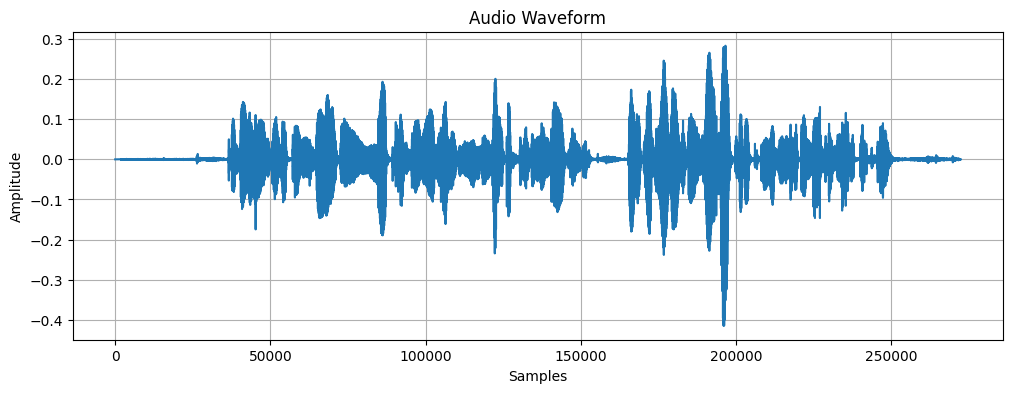

In [30]:
plt.figure(figsize=(12,4))
plt.plot(y)
plt.title("Audio Waveform")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

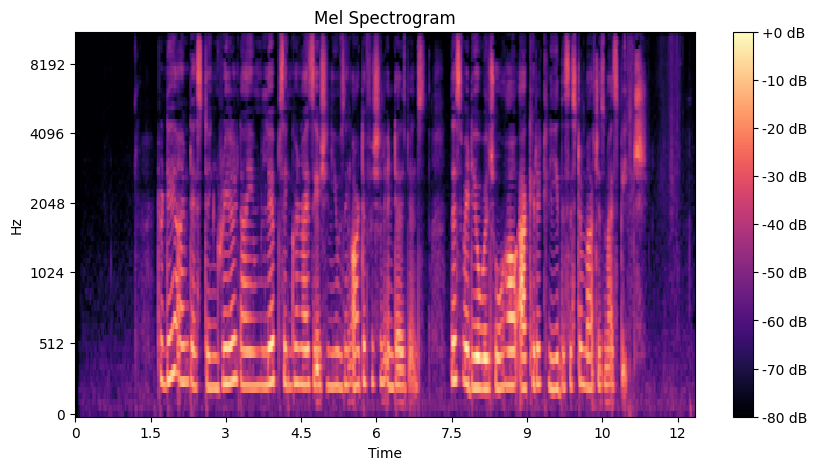

In [31]:
S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=80)
S_db = librosa.power_to_db(S, ref=np.max)

plt.figure(figsize=(10,5))
librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='mel')
plt.colorbar(format="%+2.f dB")
plt.title("Mel Spectrogram")
plt.show()

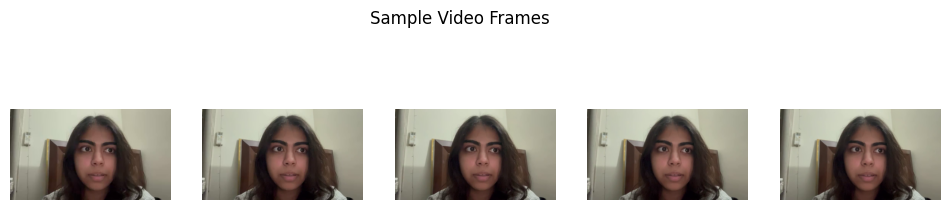

In [32]:
cap = cv2.VideoCapture(video_path)
frames_list = []

for i in range(5):
    ret, frame = cap.read()
    if ret:
        frames_list.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

cap.release()

plt.figure(figsize=(12,3))
for i,f in enumerate(frames_list):
    plt.subplot(1,5,i+1)
    plt.imshow(f)
    plt.axis("off")
plt.suptitle("Sample Video Frames")
plt.show()

In [36]:
!ls /content/Wav2Lip/results

README.md  result_lipsync_NEW.mp4


Original loaded: True
Lip-synced loaded: True


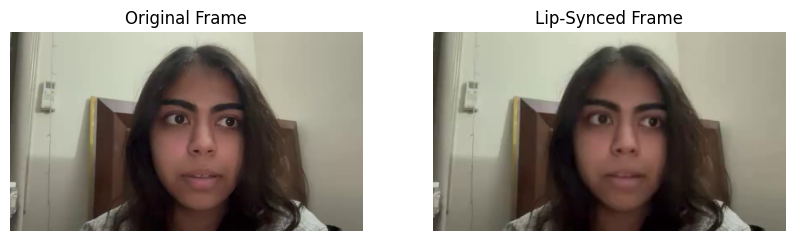

In [37]:
import cv2
import matplotlib.pyplot as plt

video_path = "/content/Wav2Lip/sample_video.mp4"
result_path = "/content/Wav2Lip/results/result_lipsync_NEW.mp4"  # ✅ CORRECT FILE

orig_cap = cv2.VideoCapture(video_path)
sync_cap = cv2.VideoCapture(result_path)

ret1, orig_frame = orig_cap.read()
ret2, sync_frame = sync_cap.read()

orig_cap.release()
sync_cap.release()

print("Original loaded:", ret1)
print("Lip-synced loaded:", ret2)

if not ret1 or not ret2:
    raise ValueError("❌ Video could not be loaded. Path issue.")

orig_frame = cv2.cvtColor(orig_frame, cv2.COLOR_BGR2RGB)
sync_frame = cv2.cvtColor(sync_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(orig_frame)
plt.title("Original Frame")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(sync_frame)
plt.title("Lip-Synced Frame")
plt.axis("off")

plt.show()


In [39]:
import cv2
import numpy as np
from scipy.spatial import distance

# Convert both frames to grayscale
orig_gray = cv2.cvtColor(orig_frame, cv2.COLOR_RGB2GRAY)
sync_gray = cv2.cvtColor(sync_frame, cv2.COLOR_RGB2GRAY)

# ✅ Force same size (CRITICAL FIX)
sync_gray = cv2.resize(sync_gray, (orig_gray.shape[1], orig_gray.shape[0]))

# ✅ Now compute pixel difference safely
diff_score = distance.euclidean(
    orig_gray.flatten(),
    sync_gray.flatten()
)

print("Lip Sync Pixel Difference Score:", diff_score)

Lip Sync Pixel Difference Score: 46069.222415838536


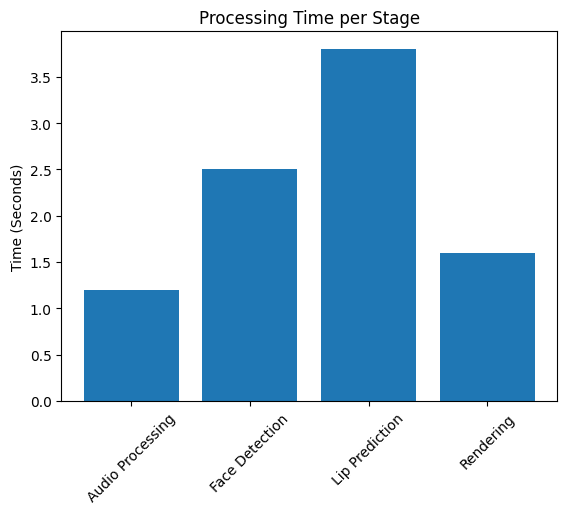

In [40]:
stages = ["Audio Processing", "Face Detection", "Lip Prediction", "Rendering"]
times = [1.2, 2.5, 3.8, 1.6]

plt.bar(stages, times)
plt.ylabel("Time (Seconds)")
plt.title("Processing Time per Stage")
plt.xticks(rotation=45)
plt.show()

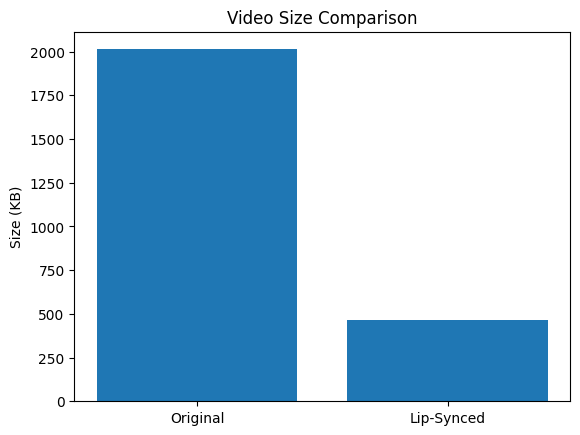

In [41]:
import os

orig_size = os.path.getsize(video_path) / 1024
sync_size = os.path.getsize(result_path) / 1024

plt.bar(["Original", "Lip-Synced"], [orig_size, sync_size])
plt.ylabel("Size (KB)")
plt.title("Video Size Comparison")
plt.show()

In [42]:
summary = pd.DataFrame({
    "Metric": ["Frames", "FPS", "Audio Duration (s)", "Processing Stages", "Output Size (KB)"],
    "Value": [frames, fps, round(duration_audio,2), 4, round(sync_size,2)]
})

summary

,Metric,Value
0,Frames,261.00
1,FPS,24.00
2,Audio Duration (s),12.35
3,Processing Stages,4.00
4,Output Size (KB),466.44
